# Space-charge test: Python vs MATLAB

Run `spacecharge_test.ipynb`, then all sections of `spacecharge_test.mlx`, then **Restart Kernel and Run All** here.

This notebook reads saved results only. It compares **local Python to local MATLAB** and **global Python to global MATLAB**, including DC, complex RF harmonics, prefill, radial-mode factors, prescribed sources and reconstructed snapshots. It does not impose equality between the two space-charge approximations.

Case/profile labels and run IDs must match. After a Python export, rerun MATLAB; the previous MATLAB result is stale.


In [1]:
from pathlib import Path
from datetime import datetime

import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
from IPython.display import Markdown, display

current_directory = Path.cwd().resolve()
project_directory = next(
    path
    for parent in (current_directory, *current_directory.parents)
    for path in (parent, parent / "pyKlyC")
    if (path / "src" / "solver" / "grid.py").exists()
)
test_directory = project_directory / "test" / "6.spacecharge_test"

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.grid": True,
    "axes.axisbelow": "line",
    "grid.color": "gray",
    "grid.linestyle": "--",
    "grid.linewidth": 0.7,
    "grid.alpha": 0.45,
})


In [2]:
python_file = test_directory / "python_results.mat"
matlab_file = test_directory / "matlab_results.mat"
for result_file in (python_file, matlab_file):
    if not result_file.is_file():
        raise FileNotFoundError(f"Missing {result_file}. Run both space-charge tests first.")
    modified = datetime.fromtimestamp(result_file.stat().st_mtime)
    print(f"{result_file.name}: {result_file}")
    print(f"  Last modified (local time): {modified:%Y-%m-%d %H:%M:%S}")

python_results = loadmat(python_file)
matlab_results = loadmat(matlab_file)


python_results.mat: C:\Users\lsito\Desktop\PyKlyC\pyKlyC\test\6.spacecharge_test\python_results.mat
  Last modified (local time): 2026-10-16 13:25:36
matlab_results.mat: C:\Users\lsito\Desktop\PyKlyC\pyKlyC\test\6.spacecharge_test\matlab_results.mat
  Last modified (local time): 2026-10-16 13:26:51


## 1. Comparison rules

Compare every exported entry using rtol=1e-10 and atol=1e-12, retaining complex signs/phases. Only declared vectors may ignore row/column orientation. Empty upstream matrices must retain shape (0, Ns+1).

Counts, controls and Nesz are exact. For Nesz, add 1 to **only the first column of a copy of Python's result**: its exclusive stop is already numerically equal to MATLAB's inclusive endpoint. No field or coordinate rescaling is applied.

Missing, nonfinite, wrongly shaped, or extra untested outputs prevent a pass.


In [3]:
rtol, atol = 1e-10, 1e-12
variables = {
    "Iz0": ("scalar", "A"), "I0": ("scalar", "A"), "U0": ("scalar", "kV"),
    "s": ("scalar", "1"), "vetoc": ("samples", "1"), "vn1": ("samples", "1"),
    "gama": ("scalar", "1"),
    "w": ("scalar", "rad/s"), "betae": ("scalar", "1/mm"), "dz": ("scalar", "mm"),
    "zi": ("nodes", "mm"), "z": ("nodes", "1"), "dt": ("scalar", "1"),
    "rcvs": ("nodes", "mm"), "dN": ("count_zero", "intervals"), "Nesz": ("windows", "indices"),
    "IzDC": ("nodes", "1"), "Iz": ("grid_harmonics", "1"),
    "QQDC": ("nodes", "1"), "QQ": ("grid_harmonics", "1"),
    "vez": ("nodes", "1"), "gamaz": ("nodes", "1"),
    "wp": ("scalar", "rad/s"), "zp": ("upstream", "1"), "gamazp": ("upstream", "1"),
    "QQfill": ("upstream", "1"), "Esz00": ("grid_dc_rf", "1"), "Eszr": ("radial_modes", "mm^2"),
    "Esz_local": ("grid_harmonics", "1"), "Esz0_local": ("nodes", "1"),
    "Esztotal_local": ("grid_dc_rf", "1"), "Esz_global": ("grid_harmonics", "1"),
    "Esz0_global": ("nodes", "1"), "Esztotal_global": ("grid_dc_rf", "1"),
    "E_local": ("grid_snapshots", "1"), "E_global": ("grid_snapshots", "1"),
    "Nfill": ("count_zero", "sources"), "SCmethods": ("methods", "classification"),
    "Nt": ("count", "samples"), "Ns": ("count", "harmonics"), "nn": ("count", "iteration"),
    "factor": ("scalar", "1"), "factorregion": ("scalar", "1"),
    "fillfactor": ("scalar", "1"), "DCSPfactor": ("scalar", "1"),
    "speed_drop": ("scalar", "1"), "modulation_growth": ("scalar", "1"), "theta": ("snapshots", "rad"),
}
complex_names = {
    "Iz", "QQ", "QQfill", "Esz00",
    "Esz_local", "Esz0_local", "Esztotal_local", "Esz_global", "Esz0_global", "Esztotal_global",
}
exact_names = {
    "Nt", "Ns", "nn", "Nfill", "dN", "Nesz", "SCmethods", "factor", "factorregion",
    "fillfactor", "DCSPfactor", "speed_drop", "modulation_growth", "theta",
}
matrix_structures = {"windows", "grid_harmonics", "grid_dc_rf", "upstream", "radial_modes", "grid_snapshots"}
text_names = {"case_name", "beam_profile", "run_id"}

def get_count(results, name):
    values = results.get(name, np.array([]))
    if values.shape != (1, 1) or values.dtype.kind not in "iuf":
        return -1
    value = values.item()
    minimum = 0 if name in ("dN", "Nfill") else 1
    return int(value) if np.isfinite(value) and value >= minimum and value == np.floor(value) else -1

def expected_shape(results, structure):
    nodes = results.get("zi", np.array([])).size
    snapshots = results.get("theta", np.array([])).size
    Ns = get_count(results, "Ns")
    return {
        "windows": (nodes, 2), "grid_harmonics": (nodes, Ns),
        "grid_dc_rf": (nodes, Ns+1), "upstream": (get_count(results,"Nfill"), Ns+1),
        "radial_modes": (nodes, 5), "grid_snapshots": (nodes, snapshots),
        "samples": (get_count(results,"Nt"),), "nodes": (nodes,),
        "snapshots": (snapshots,), "methods": (2,), "scalar": (1,), "count": (1,), "count_zero": (1,),
    }[structure]


In [4]:
text_matches = True
for name in sorted(text_names):
    values = []
    for results in (python_results, matlab_results):
        value = results.get(name, np.array([]))
        values.append(value.item() if value.size == 1 and value.dtype.kind in "US" else "")
    matched = bool(values[0]) and values[0] == values[1]
    text_matches = text_matches and matched
    print(f"{name}: Python={values[0]!r}; MATLAB={values[1]!r}; match={matched}")

comparison = []
pairs = {}
for name, (structure, units) in variables.items():
    python_values = python_results.get(name)
    matlab_values = matlab_results.get(name)
    row = {
        "name": name, "units": units,
        "python_shape": None if python_values is None else python_values.shape,
        "matlab_shape": None if matlab_values is None else matlab_values.shape,
        "max_absolute": None, "max_relative": None,
        "status": "NOT TESTED", "note": "",
    }
    comparison.append(row)
    if python_values is None or matlab_values is None:
        row["note"] = "Missing variable."
        continue
    allowed_types = "iufc" if name in complex_names else "iuf"
    if any(values.dtype.kind not in allowed_types for values in (python_values, matlab_values)):
        row["note"] = "Unexpected data type."
        continue

    shape_ok = True
    for values, results in ((python_values, python_results), (matlab_values, matlab_results)):
        shape = expected_shape(results, structure)
        if structure == "upstream":
            shape_ok = shape_ok and shape[0] >= 0 and shape[1] >= 2
        else:
            shape_ok = shape_ok and all(dimension >= 1 for dimension in shape)
        if structure in matrix_structures:
            shape_ok = shape_ok and values.shape == shape
        else:
            shape_ok = shape_ok and values.ndim == 2 and 1 in values.shape and values.size == shape[0]
    if not shape_ok:
        row["note"] = f"Unexpected {structure} dimensions."
        continue

    dtype = complex if name in complex_names else float
    python_values, matlab_values = python_values.astype(dtype), matlab_values.astype(dtype)
    if structure not in matrix_structures:
        python_values, matlab_values = python_values.reshape(-1), matlab_values.reshape(-1)
    if python_values.shape != matlab_values.shape:
        row["note"] = "Different dimensions."
        continue
    if not (np.all(np.isfinite(python_values)) and np.all(np.isfinite(matlab_values))):
        row["note"] = "NaN or infinity found."
        continue
    if structure in ("count", "count_zero") and (get_count(python_results, name) < 0 or get_count(matlab_results, name) < 0):
        row["note"] = "Invalid integer count."
        continue

    if name == "Nesz":
        python_values[:, 0] += 1  # Only the start index changes convention.
        node_count = python_results["zi"].size
        nodes = np.arange(1, node_count+1)
        windows_ok = True
        for values, results in ((python_values, python_results), (matlab_values, matlab_results)):
            dN = get_count(results, "dN")
            expected = np.column_stack((np.maximum(1,nodes-dN), np.minimum(node_count,nodes+dN)))
            windows_ok = windows_ok and dN >= 0 and np.array_equal(values, expected)
        if not windows_ok:
            row["note"] = "Invalid source-window indices after conversion."
            continue
    pairs[name] = (python_values, matlab_values)
    error = np.abs(python_values - matlab_values)
    row["max_absolute"] = np.max(error) if error.size else 0.0
    nonzero = matlab_values != 0
    if np.any(nonzero):
        row["max_relative"] = np.max(error[nonzero] / np.abs(matlab_values[nonzero]))
    if name in exact_names:
        passed = np.array_equal(python_values, matlab_values)
        row["note"] = "Exact values (+1 to Python start index)" if name == "Nesz" else "Exact values"
    else:
        passed = np.all(error <= atol + rtol * np.abs(matlab_values))
        row["note"] = "Absolute + relative tolerance"
    row["status"] = "PASS" if passed else "FAIL"

exported_names = {
    name for results in (python_results, matlab_results) for name in results if not name.startswith("__")
}
extra_names = sorted(exported_names - variables.keys() - text_names)
metadata_ok = all(
    get_count(results,"dN") == get_count(results,"Nfill") >= 0
    and np.array_equal(results.get("SCmethods",np.array([])).reshape(-1), [0,1])
    for results in (python_results,matlab_results)
)
all_passed = text_matches and metadata_ok and all(row["status"] == "PASS" for row in comparison) and not extra_names


beam_profile: Python='constant_speed'; MATLAB='constant_speed'; match=True
case_name: Python='modulated'; MATLAB='modulated'; match=True
run_id: Python='2e6dc63fff8e4d78b1c9cc8af87f26a6'; MATLAB='2e6dc63fff8e4d78b1c9cc8af87f26a6'; match=True


## 2. Numerical summary

A large relative error near a zero coefficient can still pass when its absolute error is within tolerance. The actual rule checks every entry, including zeros. Both methods have separate result rows.


In [5]:
def format_error(value):
    return "-" if value is None else f"{value:.3e}"

table = [
    "| Variable | Units | Python shape | MATLAB shape | Max absolute error | Max relative error | Result | Rule / issue |",
    "|---|---|---|---|---|---|---|---|",
]
for row in comparison:
    table.append(
        f"| {row['name']} | {row['units']} | {row['python_shape']} | {row['matlab_shape']} "
        f"| {format_error(row['max_absolute'])} | {format_error(row['max_relative'])} "
        f"| {row['status']} | {row['note']} |"
    )
display(Markdown("\n".join(table)))
print("Case, beam profile and run ID match:", text_matches)
if extra_names:
    print("NOT TESTED: unexpected exported variables:", ", ".join(extra_names))
passed_count = sum(row["status"] == "PASS" for row in comparison)
print(f"Tolerance: rtol={rtol:g}, atol={atol:g}")
print(f"{passed_count}/{len(variables)} numerical outputs/metadata passed.")
print("Overall: PASS" if all_passed else "Overall: NOT PASSED — inspect the table above.")


| Variable | Units | Python shape | MATLAB shape | Max absolute error | Max relative error | Result | Rule / issue |
|---|---|---|---|---|---|---|---|
| Iz0 | A | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| I0 | A | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| U0 | kV | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| s | 1 | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| vetoc | 1 | (1, 128) | (1, 128) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| vn1 | 1 | (1, 128) | (1, 128) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| gama | 1 | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| w | rad/s | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| betae | 1/mm | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| dz | mm | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| zi | mm | (1, 3806) | (3806, 1) | 4.547e-13 | 2.334e-16 | PASS | Absolute + relative tolerance |
| z | 1 | (1, 3806) | (3806, 1) | 1.421e-14 | 2.343e-16 | PASS | Absolute + relative tolerance |
| dt | 1 | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| rcvs | mm | (1, 3806) | (3806, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| dN | intervals | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Exact values |
| Nesz | indices | (3806, 2) | (3806, 2) | 0.000e+00 | 0.000e+00 | PASS | Exact values (+1 to Python start index) |
| IzDC | 1 | (1, 3806) | (3806, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| Iz | 1 | (3806, 8) | (3806, 8) | 2.866e-15 | 7.090e-02 | PASS | Absolute + relative tolerance |
| QQDC | 1 | (1, 3806) | (3806, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| QQ | 1 | (3806, 8) | (3806, 8) | 2.866e-15 | 7.090e-02 | PASS | Absolute + relative tolerance |
| vez | 1 | (1, 3806) | (3806, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| gamaz | 1 | (1, 3806) | (3806, 1) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| wp | rad/s | (1, 1) | (1, 1) | 4.768e-07 | 1.278e-16 | PASS | Absolute + relative tolerance |
| zp | 1 | (52, 9) | (52, 9) | 8.882e-16 | 2.130e-16 | PASS | Absolute + relative tolerance |
| gamazp | 1 | (52, 9) | (52, 9) | 0.000e+00 | 0.000e+00 | PASS | Absolute + relative tolerance |
| QQfill | 1 | (52, 9) | (52, 9) | 2.950e-16 | 7.090e-02 | PASS | Absolute + relative tolerance |
| Esz00 | 1 | (3806, 9) | (3806, 9) | 1.041e-17 | 1.000e+00 | PASS | Absolute + relative tolerance |
| Eszr | mm^2 | (3806, 5) | (3806, 5) | 2.132e-14 | 1.585e-14 | PASS | Absolute + relative tolerance |
| Esz_local | 1 | (3806, 8) | (3806, 8) | 1.833e-17 | 7.090e-02 | PASS | Absolute + relative tolerance |
| Esz0_local | 1 | (1, 3806) | (3806, 1) | 0.000e+00 | - | PASS | Absolute + relative tolerance |
| Esztotal_local | 1 | (3806, 9) | (3806, 9) | 0.000e+00 | - | PASS | Absolute + relative tolerance |
| Esz_global | 1 | (3806, 8) | (3806, 8) | 9.588e-16 | 3.627e-01 | PASS | Absolute + relative tolerance |
| Esz0_global | 1 | (1, 3806) | (3806, 1) | 4.963e-15 | 3.860e+03 | PASS | Absolute + relative tolerance |
| Esztotal_global | 1 | (3806, 9) | (3806, 9) | 4.963e-15 | 3.860e+03 | PASS | Absolute + relative tolerance |
| E_local | 1 | (3806, 4) | (3806, 4) | 2.694e-17 | 1.630e-10 | PASS | Absolute + relative tolerance |
| E_global | 1 | (3806, 4) | (3806, 4) | 5.776e-15 | 3.293e-01 | PASS | Absolute + relative tolerance |
| Nfill | sources | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Exact values |
| SCmethods | classification | (1, 2) | (1, 2) | 0.000e+00 | 0.000e+00 | PASS | Exact values |
| Nt | samples | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Exact values |
| Ns | harmonics | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Exact values |
| nn | iteration | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Exact values |
| factor | 1 | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Exact values |
| factorregion | 1 | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Exact values |
| fillfactor | 1 | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Exact values |
| DCSPfactor | 1 | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Exact values |
| speed_drop | 1 | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Exact values |
| modulation_growth | 1 | (1, 1) | (1, 1) | 0.000e+00 | 0.000e+00 | PASS | Exact values |
| theta | rad | (1, 4) | (1, 4) | 0.000e+00 | 0.000e+00 | PASS | Exact values |

Case, beam profile and run ID match: True
Tolerance: rtol=1e-10, atol=1e-12
48/48 numerical outputs/metadata passed.
Overall: PASS


## 3. Each method against MATLAB: DC and first RF harmonic

Solid curves are Python and dashed curves are MATLAB. The right panels show complex differences. The table above checks every retained harmonic and node, not only these displayed examples.


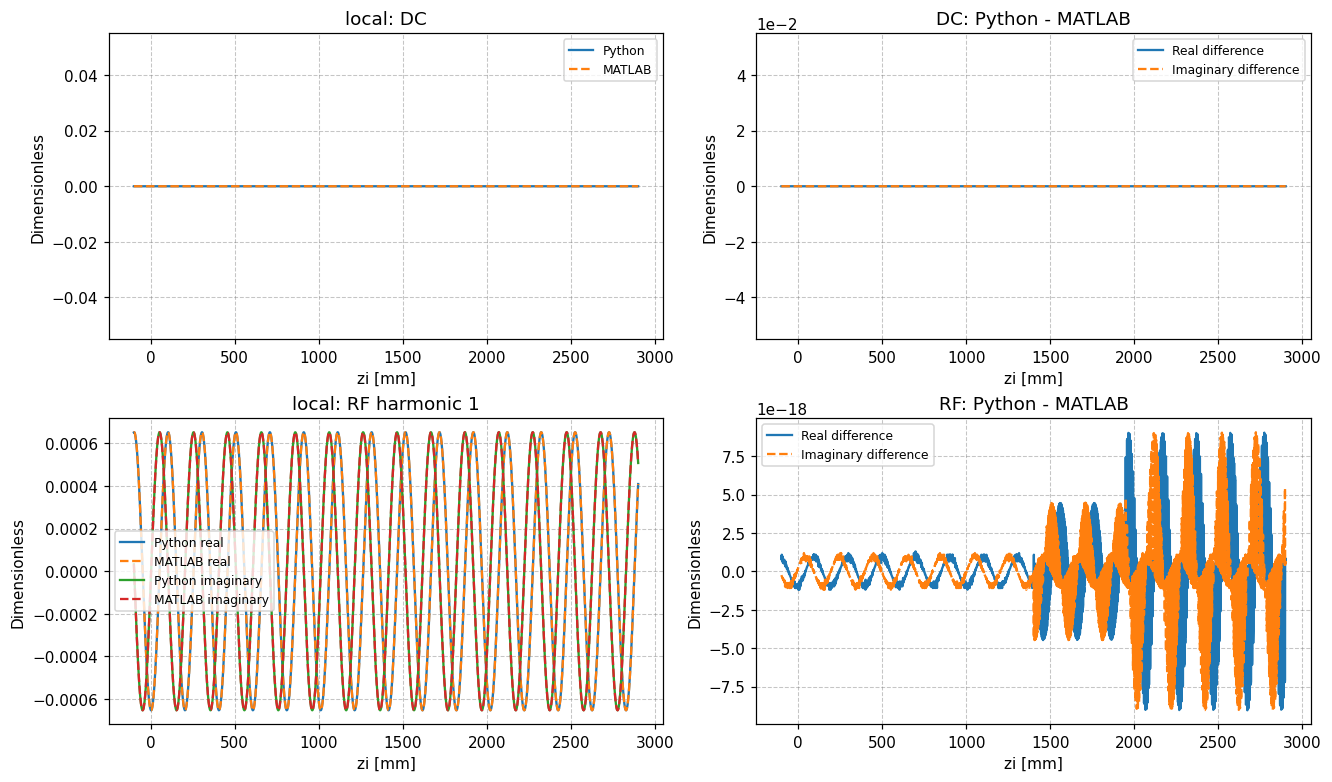

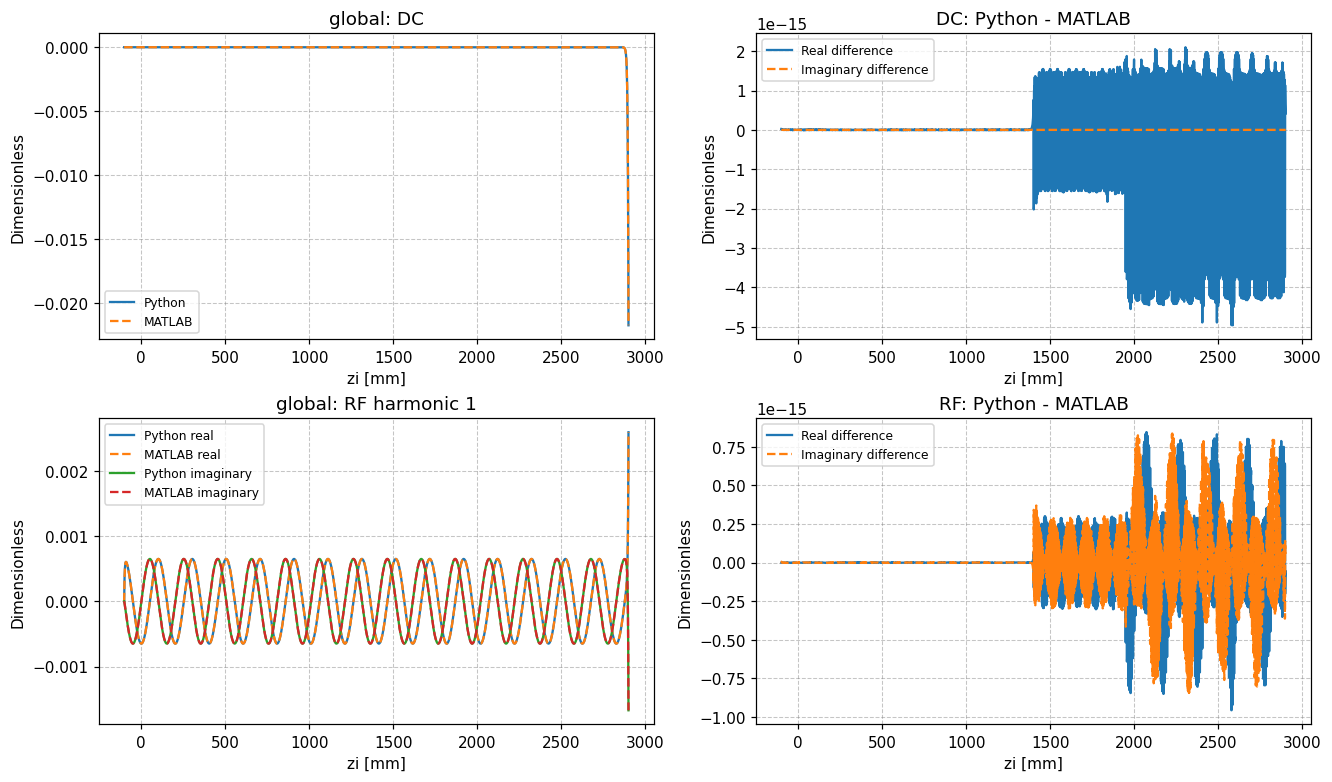

In [6]:
required = ("zi", "Esz_local", "Esz_global", "Esz0_local", "Esz0_global")
if all(name in pairs for name in required):
    zi = pairs["zi"][0]
    for label in ("local", "global"):
        fig, axes = plt.subplots(2,2,figsize=(12,7),layout="constrained")
        py_dc, ma_dc = pairs[f"Esz0_{label}"]
        py_rf, ma_rf = pairs[f"Esz_{label}"]
        axes[0,0].plot(zi,py_dc.real,label="Python")
        axes[0,0].plot(zi,ma_dc.real,"--",label="MATLAB")
        axes[0,0].set_title(f"{label}: DC")
        axes[0,1].plot(zi,(py_dc-ma_dc).real,label="Real difference")
        axes[0,1].plot(zi,(py_dc-ma_dc).imag,"--",label="Imaginary difference")
        axes[0,1].set_title("DC: Python - MATLAB")
        axes[1,0].plot(zi,py_rf[:,0].real,label="Python real")
        axes[1,0].plot(zi,ma_rf[:,0].real,"--",label="MATLAB real")
        axes[1,0].plot(zi,py_rf[:,0].imag,label="Python imaginary")
        axes[1,0].plot(zi,ma_rf[:,0].imag,"--",label="MATLAB imaginary")
        axes[1,0].set_title(f"{label}: RF harmonic 1")
        difference=py_rf[:,0]-ma_rf[:,0]
        axes[1,1].plot(zi,difference.real,label="Real difference")
        axes[1,1].plot(zi,difference.imag,"--",label="Imaginary difference")
        axes[1,1].set_title("RF: Python - MATLAB")
        for ax in axes.flat:
            ax.set(xlabel="zi [mm]",ylabel="Dimensionless")
            ax.legend(fontsize=8)
        for ax in axes[:,1]:
            ax.ticklabel_format(axis="y",style="sci",scilimits=(0,0),useOffset=False)
        plt.show()


## 4. Maximum complex error by harmonic, including DC


In [7]:
if all(name in pairs for name in ("Esz_local","Esz_global","Esz0_local","Esz0_global")):
    table = ["| Method | Harmonic | Maximum complex absolute error |","|---|---|---|"]
    for label in ("local","global"):
        py_dc, ma_dc = pairs[f"Esz0_{label}"]
        py_rf, ma_rf = pairs[f"Esz_{label}"]
        errors = np.r_[np.max(np.abs(py_dc-ma_dc)),np.max(np.abs(py_rf-ma_rf),axis=0)]
        for k, error in enumerate(errors):
            table.append(f"| {label} | {k} | {error:.3e} |")
    display(Markdown("\n".join(table)))


| Method | Harmonic | Maximum complex absolute error |
|---|---|---|
| local | 0 | 0.000e+00 |
| local | 1 | 9.232e-18 |
| local | 2 | 1.833e-17 |
| local | 3 | 1.355e-19 |
| local | 4 | 1.998e-20 |
| local | 5 | 1.405e-19 |
| local | 6 | 1.849e-19 |
| local | 7 | 2.768e-19 |
| local | 8 | 1.059e-19 |
| global | 0 | 4.963e-15 |
| global | 1 | 9.588e-16 |
| global | 2 | 4.669e-16 |
| global | 3 | 2.207e-19 |
| global | 4 | 2.512e-20 |
| global | 5 | 1.462e-19 |
| global | 6 | 1.857e-19 |
| global | 7 | 2.802e-19 |
| global | 8 | 1.083e-19 |

## 5. Global source-window bookkeeping and field snapshots

Nesz values below are shown after the documented indexing conversion. Snapshot errors include DC and all RF harmonics.


| Target (Python index) | Python converted window | MATLAB window |
|---|---|---|
| 0 | [ 1 53] | [ 1 53] |
| 1903 | [1852 1956] | [1852 1956] |
| 3805 | [3754 3806] | [3754 3806] |

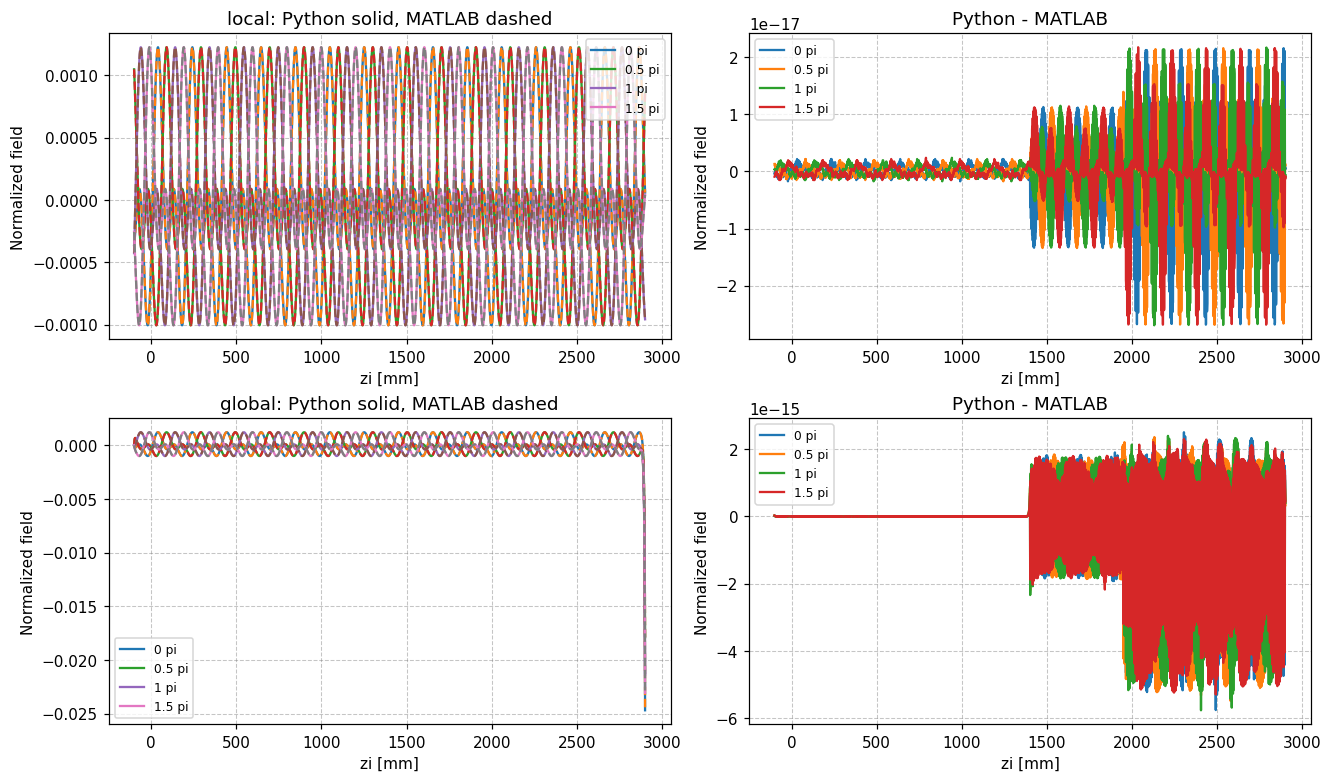

In [8]:
if "Nesz" in pairs:
    py, ma = pairs["Nesz"]
    indices = np.unique([0,len(py)//2,len(py)-1])
    table = ["| Target (Python index) | Python converted window | MATLAB window |","|---|---|---|"]
    for index in indices:
        table.append(f"| {index} | {py[index].astype(int)} | {ma[index].astype(int)} |")
    display(Markdown("\n".join(table)))
if all(name in pairs for name in ("zi","theta","E_local","E_global")):
    fig,axes=plt.subplots(2,2,figsize=(12,7),layout="constrained")
    for row,label in enumerate(("local","global")):
        py,ma=pairs[f"E_{label}"]
        for j,phase in enumerate(pairs["theta"][0]):
            axes[row,0].plot(pairs["zi"][0],py[:,j],label=f"{phase/np.pi:g} pi")
            axes[row,0].plot(pairs["zi"][1],ma[:,j],"--")
            axes[row,1].plot(pairs["zi"][0],py[:,j]-ma[:,j],label=f"{phase/np.pi:g} pi")
        axes[row,0].set_title(f"{label}: Python solid, MATLAB dashed")
        axes[row,1].set_title("Python - MATLAB")
        for ax in axes[row]:
            ax.set(xlabel="zi [mm]",ylabel="Normalized field")
            ax.legend(fontsize=8)
    plt.show()


## 6. Final result

A pass establishes numerical translation agreement for both space-charge branches on this prescribed beam. It does not validate beam dynamics, nonlinear convergence, the local approximation's accuracy, or a variable-radius model.

The known original enabled-prefill dN=1 issue is guarded in both producers. The test's MATLAB syntax/serial-execution adapters are documented in the .m file and README.


In [ ]:
assert all_passed, "Space-charge comparison did not pass. Review the table and run IDs."
print(f"PASS: all {len(variables)} numeric outputs/settings and all three text identifiers agree.")


PASS: all 48 numeric outputs/settings and all three text identifiers agree.


: 